 # Library yang digunakan:
- NumPy: mengolah citra sebagai array angka.
- Pillow: membaca dan membuat gambar.
- Matplotlib: menampilkan gambar, matriks, dan grafik.
- files: mengunggah serta mengunduh file melalui Google Colab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from pathlib import Path
import json

# Menggunggah Gambar

Saving VINCENT KEPALA DUA.jpg to VINCENT KEPALA DUA.jpg
Gambar berhasil dibaca!
Nama file: VINCENT KEPALA DUA.jpg


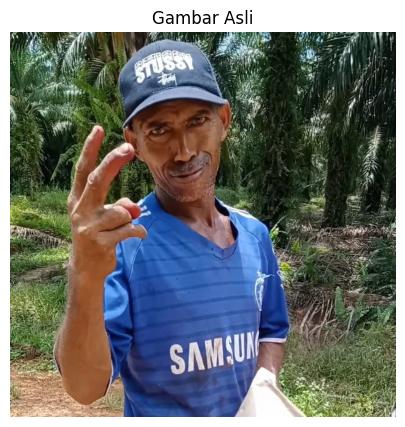

In [2]:
uploaded = files.upload()

# Mengambil nama file yang diunggah
nama_file = next(iter(uploaded.keys()))

# Membaca gambar dan mengubahnya ke format RGB
gambar = Image.open(nama_file).convert("RGB")
citra = np.array(gambar)

print("Gambar berhasil dibaca!")
print("Nama file:", nama_file)

plt.figure(figsize=(7, 5))
plt.imshow(citra)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()


Penjelasan: gambar yang awalnya terlihat sebagai foto diubah menjadi citra, yaitu array tiga dimensi yang menyimpan nilai numerik setiap piksel.

# Membuktikan gambar tersusun dari angka

In [3]:
tinggi, lebar, kanal = citra.shape
jumlah_nilai = citra.size
ukuran_byte = citra.nbytes

print("=== INFORMASI CITRA DIGITAL ===")
print(f"Lebar gambar          : {lebar} piksel")
print(f"Tinggi gambar         : {tinggi} piksel")
print(f"Jumlah kanal warna    : {kanal}")
print(f"Bentuk array          : {citra.shape}")
print(f"Tipe data             : {citra.dtype}")
print(f"Jumlah seluruh nilai : {jumlah_nilai:,}")
print(f"Ukuran array mentah   : {ukuran_byte:,} byte")
print(f"Ukuran array dalam KB : {ukuran_byte / 1024:.2f} KB")
print(f"Nilai minimum         : {citra.min()}")
print(f"Nilai maksimum        : {citra.max()}")

print("\nRumus jumlah nilai:")
print(f"{tinggi} x {lebar} x {kanal} = {jumlah_nilai:,}")


=== INFORMASI CITRA DIGITAL ===
Lebar gambar          : 736 piksel
Tinggi gambar         : 736 piksel
Jumlah kanal warna    : 3
Bentuk array          : (736, 736, 3)
Tipe data             : uint8
Jumlah seluruh nilai : 1,625,088
Ukuran array mentah   : 1,625,088 byte
Ukuran array dalam KB : 1587.00 KB
Nilai minimum         : 0
Nilai maksimum        : 255

Rumus jumlah nilai:
736 x 736 x 3 = 1,625,088


Penjelasan: jika gambar berukuran 100 × 100 piksel dengan tiga kanal RGB, jumlah nilai warnanya adalah 30.000. Setiap kanal pada gambar RGB 8-bit memiliki nilai dari 0 sampai 255.

Perlu dibedakan: ukuran array mentah bukan ukuran file JPG atau PNG di penyimpanan, karena file gambar dapat dikompresi.

# Menampilkan angka dari setiap piksel

=== NILAI SATU PIKSEL ===
Posisi piksel (x, y): (368, 368)
Nilai RGB: [151, 113, 110]
Nilai merah (R): 151
Nilai hijau (G): 113
Nilai biru (B): 110


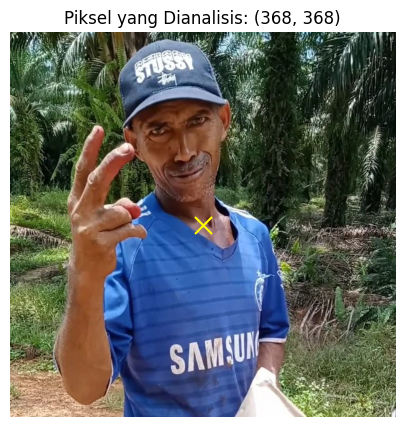

In [4]:
# Mengambil piksel di tengah gambar
y = tinggi // 2
x = lebar // 2

nilai_rgb = citra[y, x]

print("=== NILAI SATU PIKSEL ===")
print(f"Posisi piksel (x, y): ({x}, {y})")
print(f"Nilai RGB: {nilai_rgb.tolist()}")
print(f"Nilai merah (R): {int(nilai_rgb[0])}")
print(f"Nilai hijau (G): {int(nilai_rgb[1])}")
print(f"Nilai biru (B): {int(nilai_rgb[2])}")

# Menampilkan gambar dengan lokasi piksel yang dipilih
plt.figure(figsize=(7, 5))
plt.imshow(citra)
plt.scatter(x, y, color="yellow", marker="x", s=150)
plt.title(f"Piksel yang Dianalisis: ({x}, {y})")
plt.axis("off")
plt.show()


Contoh jika program menemukan nilai RGB [255, 0, 0], artinya piksel tersebut berwarna merah murni. Nilai sebenarnya akan mengikuti gambar yang kita unggah.

# Menampilkan matriks angka RGB

=== MATRIKS RGB ===
[[[112 126 101]
  [ 60  74  49]
  [ 21  35  10]
  [ 41  55  30]
  [ 62  76  51]]

 [[ 78  92  67]
  [ 45  59  34]
  [ 25  39  14]
  [ 23  37  12]
  [ 41  55  30]]

 [[ 67  81  56]
  [ 33  47  22]
  [ 28  42  17]
  [ 23  37  12]
  [ 64  78  53]]

 [[ 55  69  44]
  [ 47  61  36]
  [ 65  79  54]
  [ 58  72  47]
  [117 131 106]]

 [[ 31  45  22]
  [ 59  73  50]
  [ 97 111  88]
  [105 119  96]
  [162 176 153]]]


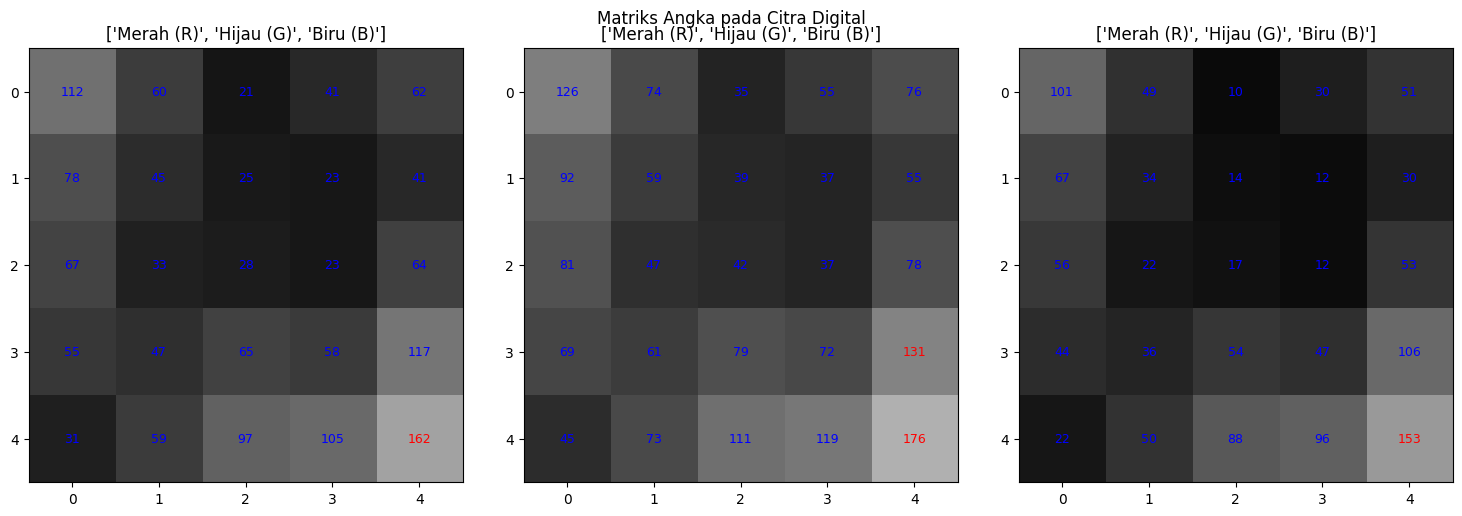

In [5]:
# Mengambil area maksimal 5 x 5 piksel
ukuran = min(5, tinggi, lebar)
matriks_rgb = citra[:ukuran, :ukuran, :]

print("=== MATRIKS RGB ===")
print(matriks_rgb)

# Menampilkan matriks untuk setiap kanal warna
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
nama_kanal = ["Merah (R)", "Hijau (G)", "Biru (B)"]

for i, ax in enumerate(axes):
    matriks = matriks_rgb[:, :, i]
    ax.imshow(matriks, cmap="gray", vmin=0, vmax=255)

    for baris in range(ukuran):
        for kolom in range(ukuran):
            ax.text(
                kolom, baris, str(int(matriks[baris, kolom])),
                ha="center", va="center", fontsize=9,
                color="red" if matriks[baris, kolom] > 127 else "blue"
            )

    ax.set_title(nama_kanal)
    ax.set_xticks(range(ukuran))
    ax.set_yticks(range(ukuran))

plt.suptitle("Matriks Angka pada Citra Digital")
plt.tight_layout()
plt.show()


Penjelasan: setiap posisi pada matriks mewakili satu piksel. Ketiga matriks menunjukkan nilai merah, hijau, dan biru dari piksel yang sama. Ketiga nilai tersebut digabungkan untuk menghasilkan warna piksel pada gambar RGB.

# Mengubah gambar menjadi grayscale

=== CITRA GRAYSCALE ===
Bentuk array RGB      : (736, 736, 3)
Bentuk array grayscale: (736, 736)
Tipe data grayscale   : uint8
Nilai minimum         : 0
Nilai maksimum        : 255

Contoh matriks grayscale:
[[119  67  28  48  69]
 [ 85  52  32  30  48]
 [ 74  40  35  30  71]
 [ 62  54  72  65 124]
 [ 38  66 104 112 169]]


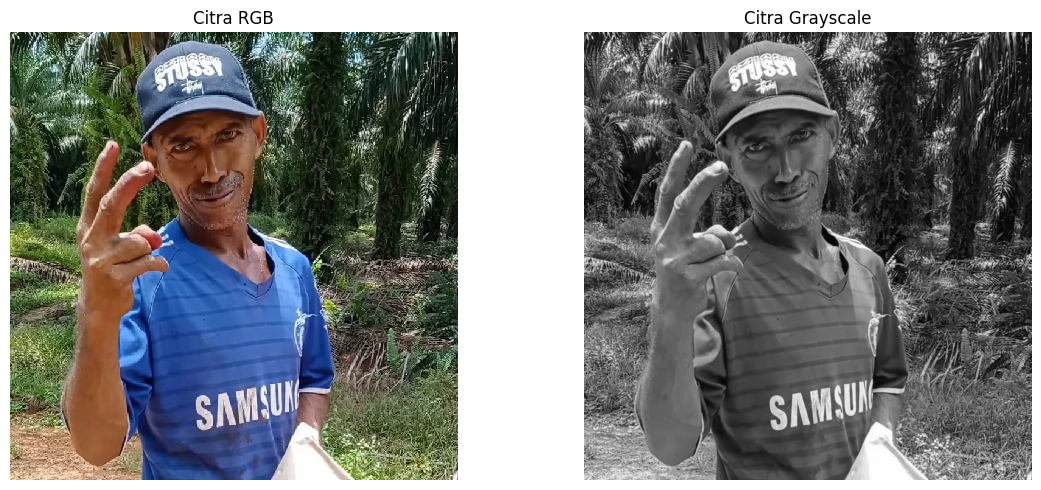

In [6]:
# Mengubah RGB menjadi grayscale
gambar_gray = gambar.convert("L")
citra_gray = np.array(gambar_gray)

print("=== CITRA GRAYSCALE ===")
print("Bentuk array RGB      :", citra.shape)
print("Bentuk array grayscale:", citra_gray.shape)
print("Tipe data grayscale   :", citra_gray.dtype)
print("Nilai minimum         :", citra_gray.min())
print("Nilai maksimum        :", citra_gray.max())

print("\nContoh matriks grayscale:")
print(citra_gray[:5, :5])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(citra, interpolation="nearest")
axes[0].set_title("Citra RGB")
axes[0].axis("off")

axes[1].imshow(citra_gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Citra Grayscale")
axes[1].axis("off")

plt.tight_layout()
plt.show()


Penjelasannya:
- Nilai mendekati 0 menunjukkan warna gelap.
- Nilai mendekati 255 menunjukkan warna terang.
- Nilai di antaranya menunjukkan tingkat keabuan.

Pada grayscale 8-bit, satu piksel hanya memerlukan satu nilai intensitas. Konversi ini menghasilkan representasi baru, jadi nilai grayscale tidak harus sama dengan nilai RGB sebelumnya.

# Rekonstruksi gambar dari angka

=== HASIL PEMBUKTIAN ===
Array gambar asli       : (736, 736, 3)
Array hasil rekonstruksi: (736, 736, 3)
Semua nilai piksel sama : True
Selisih maksimum nilai  : 0


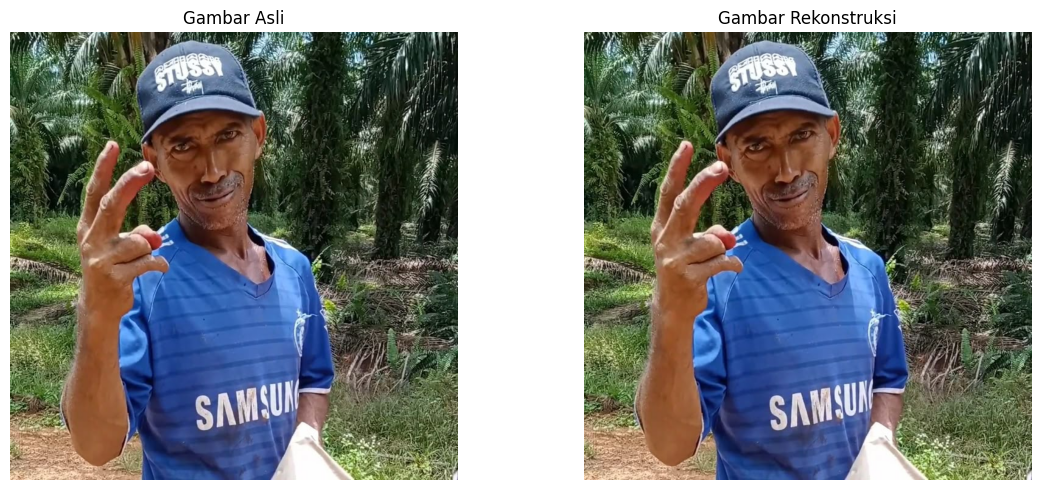


KESIMPULAN: Seluruh nilai piksel berhasil dipertahankan.


In [7]:
# Membuat gambar kembali dari array numerik
gambar_hasil = Image.fromarray(citra)
citra_hasil = np.array(gambar_hasil)

# Membandingkan nilai setiap piksel
hasil_sama = np.array_equal(citra, citra_hasil)
selisih_maksimum = np.abs(
    citra.astype(np.int16) - citra_hasil.astype(np.int16)
).max()

print("=== HASIL PEMBUKTIAN ===")
print("Array gambar asli       :", citra.shape)
print("Array hasil rekonstruksi:", citra_hasil.shape)
print("Semua nilai piksel sama :", hasil_sama)
print("Selisih maksimum nilai  :", selisih_maksimum)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(citra)
axes[0].set_title("Gambar Asli")
axes[0].axis("off")

axes[1].imshow(citra_hasil)
axes[1].set_title("Gambar Rekonstruksi")
axes[1].axis("off")

plt.tight_layout()
plt.show()

if hasil_sama:
    print("\nKESIMPULAN: Seluruh nilai piksel berhasil dipertahankan.")
else:
    print("\nKESIMPULAN: Terdapat perbedaan nilai piksel.")


Jika hasilnya True dan selisih maksimum 0, berarti semua nilai RGB identik. Ini menunjukkan bahwa gambar tersebut dapat direpresentasikan oleh array numerik dan direkonstruksi kembali tanpa mengubah nilai pikselnya.

# Menyimpan hasil untuk dikumpulkan

In [8]:
from pathlib import Path
import shutil

folder_hasil = Path("hasil_pembuktian_citra")
folder_hasil.mkdir(exist_ok=True)

# Simpan gambar-gambar hasil eksperimen
gambar.save(folder_hasil / "gambar_asli.png")
gambar_gray.save(folder_hasil / "gambar_grayscale.png")
gambar_hasil.save(folder_hasil / "gambar_rekonstruksi.png")

# Simpan visualisasi matriks RGB
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
nama_kanal = ["Merah (R)", "Hijau (G)", "Biru (B)"]

for i, ax in enumerate(axes):
    ax.imshow(citra[:ukuran, :ukuran, i],
              cmap="gray", vmin=0, vmax=255)
    ax.set_title(nama_kanal[i])
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    folder_hasil / "visualisasi_matriks.png",
    dpi=150,
    bbox_inches="tight"
)
plt.close(fig)

# Simpan ringkasan eksperimen
ringkasan = {
    "nama_gambar": nama_file,
    "lebar": int(lebar),
    "tinggi": int(tinggi),
    "jumlah_kanal": int(kanal),
    "bentuk_array": list(citra.shape),
    "tipe_data": str(citra.dtype),
    "jumlah_nilai": int(jumlah_nilai),
    "ukuran_array_mentah_byte": int(ukuran_byte),
    "nilai_rgb_piksel_tengah": nilai_rgb.tolist(),
    "rekonstruksi_identik": bool(hasil_sama),
    "selisih_maksimum": int(selisih_maksimum)
}

with open(folder_hasil / "ringkasan.json", "w") as f:
    json.dump(ringkasan, f, indent=4)

# Jadikan seluruh hasil satu file ZIP
file_zip = shutil.make_archive(
    "hasil_pembuktian_citra", "zip", folder_hasil
)

print("Hasil eksperimen berhasil disimpan.")
print("File:", file_zip)

files.download(file_zip)


Hasil eksperimen berhasil disimpan.
File: /content/hasil_pembuktian_citra.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>